# Customer Churn Prediction

## Define the problem
A company has **50,000 customers** and wants to know **who is going to leave (churn)** before they actually leave, so the retention team can act early.

- **Type of problem:** Binary classification
- **Target column:** `churned` (1 = customer left, 0 = customer stayed)
- **Goal:** Build a model that predicts `churned` from customer profile, spending, engagement and support data
- **Main metrics:** Recall, F1-score and ROC-AUC (accuracy alone is misleading when classes are imbalanced)

## Import the libraries

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_style("whitegrid")

## Load the data

In [7]:
# In Google Colab: upload large_dataset_1.csv using the Files panel (left side) first
df = pd.read_csv("large_dataset.csv")
df.head()

,customer_id,age,gender,marital_status,education,occupation,state,city_tier,annual_income,credit_score,...,loyalty_points,app_rating_given,days_since_last_purchase,wishlist_items,reviews_written,social_connections,notification_opt_in,risk_score,lifetime_value_est,churned
0,100000,23,Female,Widowed,Bachelors,Doctor,RJ,Tier1,274845.77,609.0,...,11588,2.0,152,5,3,465,1,73.79,27298.31,1
1,100001,65,Other,Single,Bachelors,Engineer,TN,Tier1,244988.64,694.0,...,12443,1.0,374,5,2,853,1,0.67,19334.42,1
2,100002,58,Female,Divorced,Bachelors,Business,TS,Tier1,281846.99,770.0,...,6803,2.0,305,6,2,620,0,86.44,21607.26,1
3,100003,45,Male,Divorced,Bachelors,Freelancer,KA,Tier1,988701.53,648.0,...,11781,NaN,356,4,4,913,1,40.65,9443.71,1
4,100004,44,Female,Divorced,PhD,Student,TN,Tier3,631053.61,751.0,...,1225,3.0,152,9,1,365,1,73.58,24660.05,0


## Understand the data

In [8]:
df.columns

Index(['customer_id', 'age', 'gender', 'marital_status', 'education',
       'occupation', 'state', 'city_tier', 'annual_income', 'credit_score',
       'household_size', 'num_children', 'owns_home', 'owns_car',
       'years_employed', 'signup_date', 'last_login_date', 'tenure_months',
       'plan_type', 'payment_method', 'device_type', 'os', 'browser',
       'referral_source', 'is_subscribed_newsletter', 'email_verified',
       'phone_verified', 'monthly_spend_m1', 'monthly_spend_m2',
       'monthly_spend_m3', 'monthly_spend_m4', 'monthly_spend_m5',
       'monthly_spend_m6', 'monthly_spend_m7', 'monthly_spend_m8',
       'monthly_spend_m9', 'monthly_spend_m10', 'monthly_spend_m11',
       'monthly_spend_m12', 'total_orders', 'avg_order_value', 'total_spend',
       'returns_count', 'cart_abandon_rate', 'sessions_last_30d',
       'avg_session_minutes', 'pages_per_session', 'support_tickets',
       'avg_resolution_hours', 'csat_score', 'nps_score', 'discount_usage_pct',
       '

In [9]:
df.dtypes

,0
customer_id,int64
age,int64
gender,object
marital_status,object
education,object
...,...
social_connections,int64
notification_opt_in,int64
risk_score,float64
lifetime_value_est,float64


In [10]:
df.shape

(50000, 62)

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,50000.0,124999.500000,14433.901067,100000.00,112499.7500,124999.500,137499.2500,149999.000
age,50000.0,48.462460,17.911782,18.00,33.0000,49.000,64.0000,79.000
annual_income,48418.0,478483.465356,314300.404561,37538.11,267409.2750,399668.530,598494.1850,6608171.500
credit_score,48513.0,679.465566,79.846139,368.00,626.0000,679.000,733.0000,900.000
household_size,50000.0,4.494620,2.283969,1.00,3.0000,4.000,6.0000,8.000
num_children,50000.0,1.992040,1.416113,0.00,1.0000,2.000,3.0000,4.000
owns_home,50000.0,0.596960,0.490514,0.00,0.0000,1.000,1.0000,1.000
owns_car,50000.0,0.502420,0.499999,0.00,0.0000,1.000,1.0000,1.000
years_employed,50000.0,26.650580,17.698075,0.00,11.0000,26.000,42.0000,60.000
tenure_months,50000.0,47.975640,27.418158,1.00,24.0000,48.000,72.0000,95.000


### Missing values

In [12]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
education,1466
annual_income,1582
credit_score,1487
avg_session_minutes,1458
nps_score,1475
app_rating_given,8324


### Duplicate rows

In [13]:
df.duplicated().sum()

np.int64(0)

### Unique values of the categorical columns

In [14]:
cat_check = df.select_dtypes(exclude="number").columns
for col in cat_check:
    print(col, "->", df[col].nunique(), "unique")
    if df[col].nunique() < 15:
        print(df[col].unique())
    print("-" * 40)

gender -> 3 unique
['Female' 'Other' 'Male']
----------------------------------------
marital_status -> 4 unique
['Widowed' 'Single' 'Divorced' 'Married']
----------------------------------------
education -> 5 unique
['Bachelors' 'PhD' 'High School' nan 'Masters' 'Diploma']
----------------------------------------
occupation -> 8 unique
['Doctor' 'Engineer' 'Business' 'Freelancer' 'Student' 'Teacher' 'Clerk'
 'Retired']
----------------------------------------
state -> 10 unique
['RJ' 'TN' 'TS' 'KA' 'WB' 'UP' 'MP' 'DL' 'MH' 'GJ']
----------------------------------------
city_tier -> 3 unique
['Tier1' 'Tier3' 'Tier2']
----------------------------------------
signup_date -> 2920 unique
----------------------------------------
last_login_date -> 3720 unique
----------------------------------------
plan_type -> 4 unique
['Free' 'Basic' 'Standard' 'Premium']
----------------------------------------
payment_method -> 5 unique
['Card' 'UPI' 'Wallet' 'NetBanking' 'COD']
----------------------

### Target distribution

churned
1    31917
0    18083
Name: count, dtype: int64
churned
1    0.638
0    0.362
Name: proportion, dtype: float64


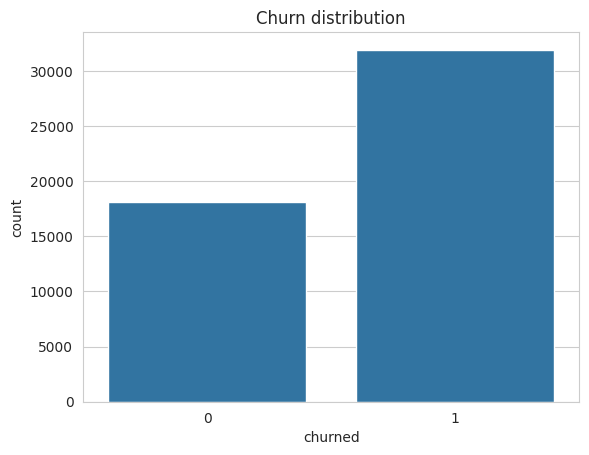

In [15]:
print(df["churned"].value_counts())
print(df["churned"].value_counts(normalize=True).round(3))
sns.countplot(x="churned", data=df)
plt.title("Churn distribution")
plt.show()

## Data cleaning
Steps:
1. Remove extra spaces from text columns
2. Drop `customer_id` (just an identifier, carries no information)
3. Convert the date columns to real dates
4. Missing values are handled later inside the pipeline (so we never leak information from the test set)

In [16]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    df[col] = df[col].str.strip()

df = df.drop(columns=["customer_id"])
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["last_login_date"] = pd.to_datetime(df["last_login_date"])
df.shape

(50000, 61)

In [17]:
# Sanity check: last_login_date should not be in the future
print("Latest signup :", df["signup_date"].max().date())
print("Latest login  :", df["last_login_date"].max().date())
print("Rows with login date after today:", (df["last_login_date"] > pd.Timestamp.today()).sum())
print("Rows with login before signup  :", (df["last_login_date"] < df["signup_date"]).sum())

Latest signup : 2025-12-29
Latest login  : 2028-06-05
Rows with login date after today: 3242
Rows with login before signup  : 0


Some `last_login_date` values are in the future (bad data), so we will **not** use the raw login date as a recency feature. We use the gap between signup and last login instead and clip it later in the outlier step.

## Exploratory Data Analysis (EDA)

### Q1. How do the numeric features compare for customers who stayed vs churned?

In [18]:
num_cols_all = df.select_dtypes(include="number").columns.drop("churned")
df.groupby("churned")[num_cols_all].mean().T.round(2)

churned,0,1
age,48.45,48.47
annual_income,478497.68,478475.41
credit_score,679.37,679.52
household_size,4.50,4.49
num_children,1.98,2.00
owns_home,0.60,0.60
owns_car,0.50,0.50
years_employed,26.64,26.66
tenure_months,47.95,47.99
is_subscribed_newsletter,0.50,0.50


### Q2. Does the time since the last purchase affect churn?

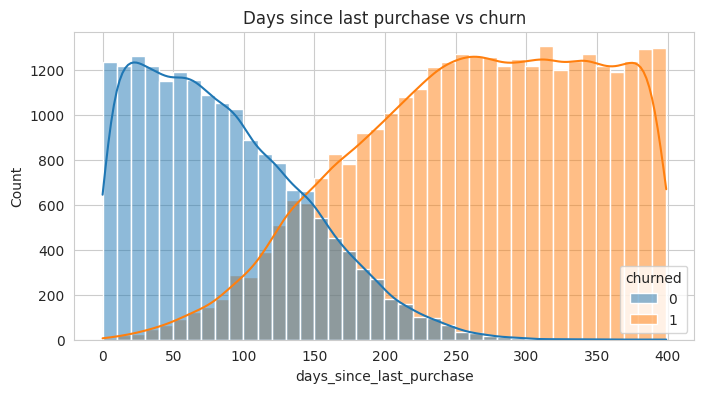

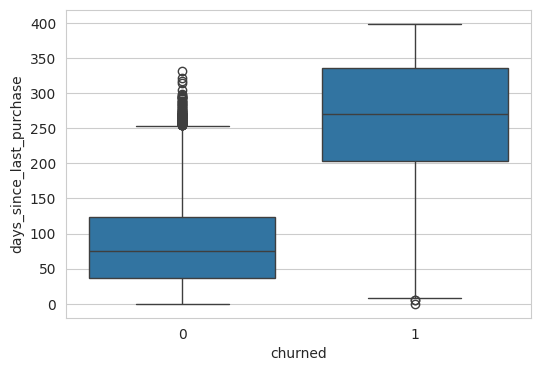

In [19]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="days_since_last_purchase", hue="churned", bins=40, kde=True)
plt.title("Days since last purchase vs churn")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x="churned", y="days_since_last_purchase", data=df)
plt.show()

### Q3. Does the plan type affect churn?

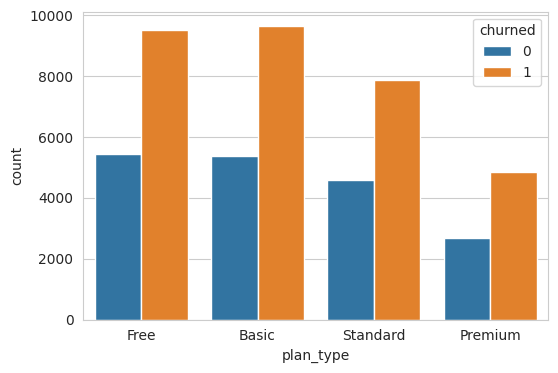

plan_type
Basic       0.642
Free        0.637
Premium     0.644
Standard    0.631
Name: churned, dtype: float64


In [20]:
plt.figure(figsize=(6, 4))
sns.countplot(x="plan_type", hue="churned", data=df, order=["Free", "Basic", "Standard", "Premium"])
plt.show()
print(df.groupby("plan_type")["churned"].mean().round(3))

### Q4. Does city tier, device or referral source matter?

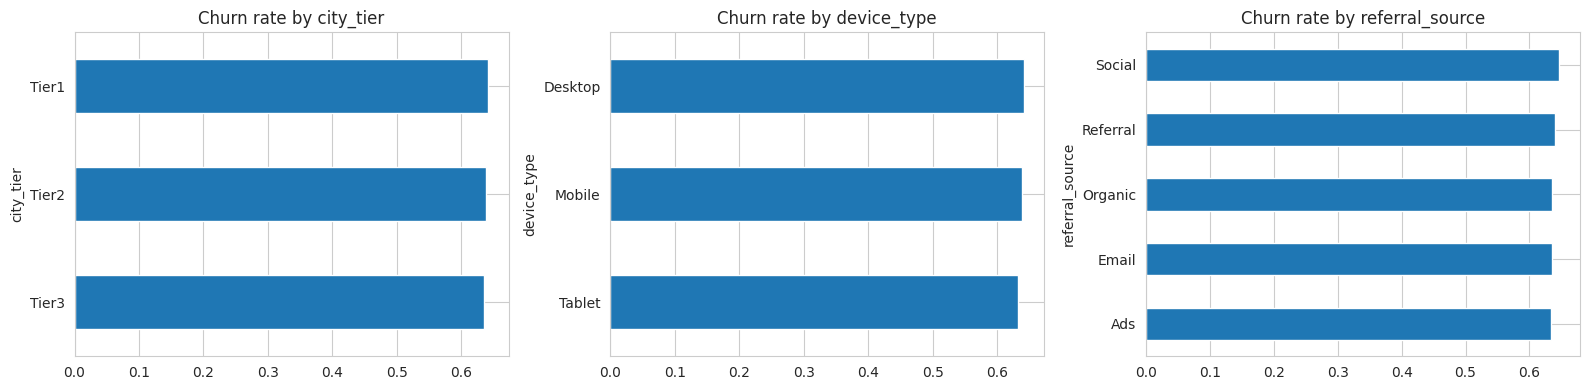

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["city_tier", "device_type", "referral_source"]):
    df.groupby(col)["churned"].mean().sort_values().plot(kind="barh", ax=a, title=f"Churn rate by {col}")
plt.tight_layout()
plt.show()

### Q5. Do support problems and satisfaction relate to churn?

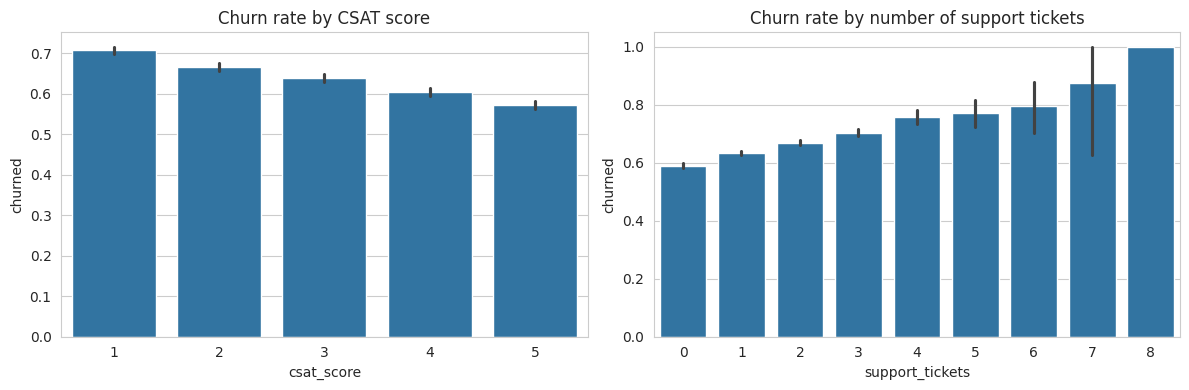

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="csat_score", y="churned", data=df, ax=ax[0])
ax[0].set_title("Churn rate by CSAT score")
sns.barplot(x="support_tickets", y="churned", data=df, ax=ax[1])
ax[1].set_title("Churn rate by number of support tickets")
plt.tight_layout()
plt.show()

### Q6. Is there any relation between spend and churn?

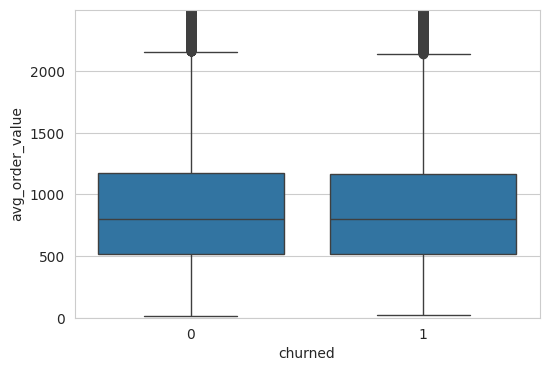

In [23]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="churned", y="avg_order_value", data=df)
plt.ylim(0, df["avg_order_value"].quantile(0.99))
plt.show()

### Q7. Which numeric features are most correlated with churn?

days_since_last_purchase    0.752441
csat_score                 -0.098100
support_tickets             0.088776
sessions_last_30d          -0.032736
monthly_spend_m9            0.009353
pages_per_session          -0.008702
monthly_spend_m2           -0.008501
monthly_spend_m8           -0.008367
lifetime_value_est         -0.007145
num_children                0.006851
monthly_spend_m6           -0.006836
email_verified             -0.005837
Name: churned, dtype: float64


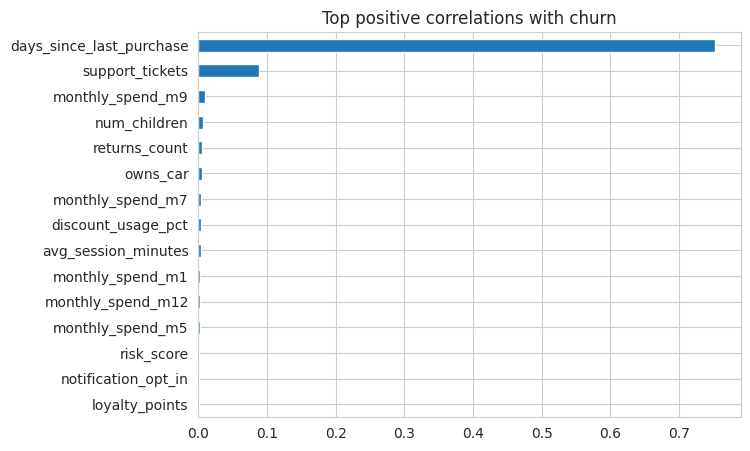

In [24]:
corr = df.select_dtypes(include="number").corr()
print(corr["churned"].drop("churned").sort_values(key=abs, ascending=False).head(12))

plt.figure(figsize=(7, 5))
corr["churned"].drop("churned").sort_values().tail(15).plot(kind="barh")
plt.title("Top positive correlations with churn")
plt.show()

**Observations**
- `days_since_last_purchase` is by far the strongest signal (customers who have not bought for a long time churn).
- `csat_score` (lower = more churn) and `support_tickets` (more = more churn) are the next useful ones.
- Plan type, city tier and the other profile columns show almost no difference in churn rate.
- `risk_score` and `lifetime_value_est` look like **outputs of another model** (already calculated using churn-like information), so using them would be data leakage. We drop them.

## Feature engineering
New columns built from the existing ones. *Assumption: `monthly_spend_m12` is the most recent month and `m1` the oldest.*

In [25]:
spend_cols = [f"monthly_spend_m{i}" for i in range(1, 13)]
early = [f"monthly_spend_m{i}" for i in (1, 2, 3)]
recent = [f"monthly_spend_m{i}" for i in (10, 11, 12)]

df["spend_mean"] = df[spend_cols].mean(axis=1)
df["spend_std"] = df[spend_cols].std(axis=1)
df["spend_trend"] = df[recent].mean(axis=1) - df[early].mean(axis=1)          # falling spend = risk
df["spend_recent_ratio"] = df[recent].mean(axis=1) / (df[early].mean(axis=1) + 1)

df["engagement"] = df["sessions_last_30d"] * df["avg_session_minutes"]
df["tickets_per_month"] = df["support_tickets"] / (df["tenure_months"] + 1)
df["orders_per_month"] = df["total_orders"] / (df["tenure_months"] + 1)
df["is_inactive"] = (df["days_since_last_purchase"] > 90).astype(int)

df["signup_year"] = df["signup_date"].dt.year
df["login_span_days"] = (df["last_login_date"] - df["signup_date"]).dt.days

df[["spend_mean", "spend_std", "spend_trend", "spend_recent_ratio", "engagement",
    "tickets_per_month", "orders_per_month", "is_inactive", "login_span_days"]].describe().T

,count,mean,std,min,25%,50%,75%,max
spend_mean,50000.0,800.884270,163.376761,280.615833,685.839792,789.397917,902.588125,1682.162500
spend_std,50000.0,541.028738,168.141701,146.279165,420.789093,520.088631,636.144915,1715.841051
spend_trend,50000.0,-0.248524,462.205404,-2165.163333,-296.516667,-1.468333,294.852500,2554.483333
spend_recent_ratio,50000.0,1.196058,0.801080,0.048446,0.669920,0.996439,1.487179,11.718679
engagement,48542.0,144.244425,113.602107,0.360000,63.140000,115.100000,193.435000,1179.290000
tickets_per_month,50000.0,0.052370,0.120819,0.000000,0.000000,0.021277,0.047619,2.500000
orders_per_month,50000.0,0.612451,1.017075,0.032258,0.188679,0.285714,0.555556,13.500000
is_inactive,50000.0,0.771740,0.419715,0.000000,1.000000,1.000000,1.000000,1.000000
login_span_days,50000.0,449.087640,259.472203,0.000000,225.000000,450.000000,672.000000,899.000000


### Drop columns we do not want
| Column(s) | Reason |
|---|---|
| `risk_score`, `lifetime_value_est` | Leakage (calculated using churn-related information) |
| `total_spend` | Almost exactly the sum of the 12 monthly columns (redundant) |
| `monthly_spend_m1` ... `m12` | Replaced by the summary spend features above |
| `signup_date`, `last_login_date` | Raw dates replaced by `signup_year` and `login_span_days` |

In [26]:
drop_cols = ["risk_score", "lifetime_value_est", "total_spend"] + spend_cols + ["signup_date", "last_login_date"]
df = df.drop(columns=drop_cols)
df.shape

(50000, 54)

## Train-test split
We split **before** outlier handling, skew handling and scaling so that nothing from the test set leaks into training. `stratify=y` keeps the churn ratio the same in both sets.

In [27]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(40000, 53) (10000, 53)
0.638 0.638


## Define the column groups

In [28]:
ordinal_col = ["plan_type", "city_tier"]
nominal_col = ["gender", "marital_status", "education", "occupation", "state",
               "payment_method", "device_type", "os", "browser", "referral_source"]

num_all = X_train.select_dtypes(include="number").columns.tolist()
binary_cols = [c for c in num_all if X_train[c].nunique() <= 2]      # 0/1 flags, left as they are
cont_cols = [c for c in num_all if c not in binary_cols]

print("Binary :", binary_cols)
print("Continuous:", len(cont_cols))

Binary : ['owns_home', 'owns_car', 'is_subscribed_newsletter', 'email_verified', 'phone_verified', 'notification_opt_in', 'is_inactive']
Continuous: 34


## Outlier handling
Check the outliers with boxplots, count them using the IQR rule, then **clip** them. The limits are calculated from the **training data only**.

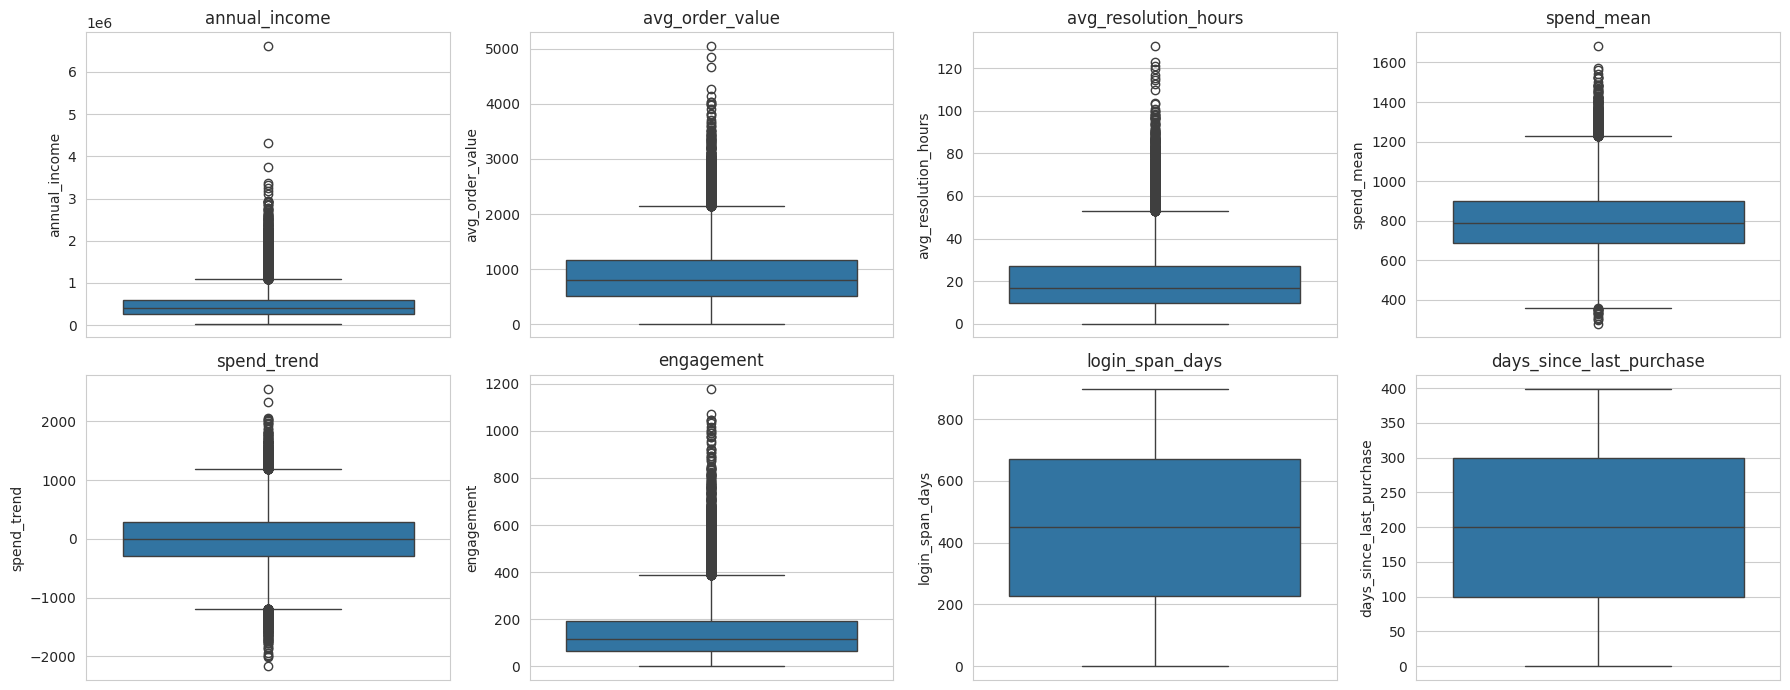

In [29]:
plot_cols = ["annual_income", "avg_order_value", "avg_resolution_hours", "spend_mean",
             "spend_trend", "engagement", "login_span_days", "days_since_last_purchase"]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, col in zip(ax.ravel(), plot_cols):
    sns.boxplot(y=X_train[col], ax=a)
    a.set_title(col)
plt.tight_layout()
plt.show()

In [30]:
def iqr_limits(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

limits = {c: iqr_limits(X_train[c]) for c in cont_cols}

outlier_count = {c: int(((X_train[c] < lo) | (X_train[c] > hi)).sum()) for c, (lo, hi) in limits.items()}
outlier_df = pd.Series(outlier_count).sort_values(ascending=False)
outlier_df[outlier_df > 0]

,0
orders_per_month,4667
tickets_per_month,3814
returns_count,2647
spend_recent_ratio,1952
annual_income,1780
engagement,1528
avg_resolution_hours,1313
avg_session_minutes,1193
avg_order_value,1055
pages_per_session,1010


In [31]:
for c, (lo, hi) in limits.items():
    X_train[c] = X_train[c].clip(lo, hi)
    X_test[c] = X_test[c].clip(lo, hi)

print("Outliers clipped using IQR limits from the training data")

Outliers clipped using IQR limits from the training data


## Skewness
Columns with `|skew| > 1` go through a `PowerTransformer` (makes them closer to a normal curve). The rest only get scaled.

In [32]:
skew = X_train[cont_cols].skew().sort_values(ascending=False)
skew

,0
tickets_per_month,1.184505
orders_per_month,1.151194
engagement,0.953126
annual_income,0.921936
spend_recent_ratio,0.920058
avg_resolution_hours,0.877955
avg_session_minutes,0.871753
support_tickets,0.847063
avg_order_value,0.753905
pages_per_session,0.748109


In [33]:
skewed_cols = skew[skew.abs() > 1].index.tolist()
numerical_cols = [c for c in cont_cols if c not in skewed_cols]
print("Skewed   :", skewed_cols)
print("Numerical:", numerical_cols)

Skewed   : ['tickets_per_month', 'orders_per_month']
Numerical: ['age', 'annual_income', 'credit_score', 'household_size', 'num_children', 'years_employed', 'tenure_months', 'total_orders', 'avg_order_value', 'returns_count', 'cart_abandon_rate', 'sessions_last_30d', 'avg_session_minutes', 'pages_per_session', 'support_tickets', 'avg_resolution_hours', 'csat_score', 'nps_score', 'discount_usage_pct', 'loyalty_points', 'app_rating_given', 'days_since_last_purchase', 'wishlist_items', 'reviews_written', 'social_connections', 'spend_mean', 'spend_std', 'spend_trend', 'spend_recent_ratio', 'engagement', 'signup_year', 'login_span_days']


## Preprocessing pipelines
| Group | Steps |
|---|---|
| Skewed numeric | median imputation -> PowerTransformer |
| Normal numeric | median imputation -> StandardScaler |
| Binary flags | most frequent imputation |
| Ordinal (`plan_type`, `city_tier`) | most frequent imputation -> OrdinalEncoder with proper order |
| Nominal | most frequent imputation -> OneHotEncoder |

In [34]:
skewed_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("power", PowerTransformer())
])

numeric_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

binary_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent"))
])

ordinal_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[["Free", "Basic", "Standard", "Premium"],
                                          ["Tier3", "Tier2", "Tier1"]]))
])

nominal_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("skewed", skewed_pipeline, skewed_cols),
    ("numeric", numeric_pipeline, numerical_cols),
    ("binary", binary_pipeline, binary_cols),
    ("ordinal", ordinal_pipeline, ordinal_col),
    ("nominal", nominal_pipeline, nominal_col),
])
preprocessor

ColumnTransformer(transformers=[('skewed',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('power',
                                                  PowerTransformer())]),
                                 ['tickets_per_month', 'orders_per_month']),
                                ('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'annual_income', 'credit_score',
                                  'household_size', 'num_children',
                                  'year...
                                                  OrdinalEncoder(categories=[['Free',
                                                                              'Basic',
                                                                              'Standard',
                                                                              'Premium'],
                                                                             ['Tier3',
                                                                              'Tier2',
                                                                              'Tier1']]))]),
                                 ['plan_type', 'city_tier']),
                                ('nominal',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'marital_status', 'education',
                                  'occupation', 'state', 'payment_method',
                                  'device_type', 'os', 'browser',
                                  'referral_source'])])

## Evaluation helper
Prints train and test scores side by side (a big gap means overfitting).

In [35]:
def evaluate(model, name):
    rows = []
    for label, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        pred = model.predict(Xs)
        proba = model.predict_proba(Xs)[:, 1]
        rows.append({
            "Model": name, "Set": label,
            "Accuracy": accuracy_score(ys, pred),
            "Precision": precision_score(ys, pred),
            "Recall": recall_score(ys, pred),
            "F1": f1_score(ys, pred),
            "ROC-AUC": roc_auc_score(ys, proba),
        })
    return pd.DataFrame(rows).round(4)

## Baseline model: Logistic Regression
`class_weight="balanced"` makes the model care more about the minority class.

In [36]:
baseline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
baseline.fit(X_train, y_train)
base_results = evaluate(baseline, "Logistic Regression")
base_results

,Model,Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Train,0.8876,0.9408,0.8794,0.9090,0.9621
1,Logistic Regression,Test,0.8807,0.9358,0.8729,0.9033,0.9591


In [37]:
print(classification_report(y_test, baseline.predict(X_test)))

              precision    recall  f1-score   support

           0       0.80      0.89      0.84      3617
           1       0.94      0.87      0.90      6383

    accuracy                           0.88     10000
   macro avg       0.87      0.88      0.87     10000
weighted avg       0.89      0.88      0.88     10000



## Best model: Random Forest + RandomizedSearchCV

In [38]:
rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("random", RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1))
])

param_grid = {
    "random__n_estimators": [100, 200, 300],
    "random__max_depth": [6, 8, 10, 12],
    "random__min_samples_split": [2, 10, 20],
    "random__min_samples_leaf": [5, 10, 20],
}

search = RandomizedSearchCV(
    rf_pipeline, param_distributions=param_grid,
    n_iter=10, cv=3, scoring="f1", random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV F1     :", round(search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'random__n_estimators': 300, 'random__min_samples_split': 2, 'random__min_samples_leaf': 5, 'random__max_depth': 12}
Best CV F1     : 0.91


In [39]:
best_model = search.best_estimator_
rf_results = evaluate(best_model, "Random Forest (tuned)")
pd.concat([base_results, rf_results], ignore_index=True)

,Model,Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Train,0.8876,0.9408,0.8794,0.9090,0.9621
1,Logistic Regression,Test,0.8807,0.9358,0.8729,0.9033,0.9591
2,Random Forest (tuned),Train,0.9134,0.9518,0.9106,0.9307,0.9773
3,Random Forest (tuned),Test,0.8818,0.9293,0.8819,0.9050,0.9533


## Final evaluation on the test set

              precision    recall  f1-score   support

           0       0.81      0.88      0.84      3617
           1       0.93      0.88      0.90      6383

    accuracy                           0.88     10000
   macro avg       0.87      0.88      0.87     10000
weighted avg       0.89      0.88      0.88     10000



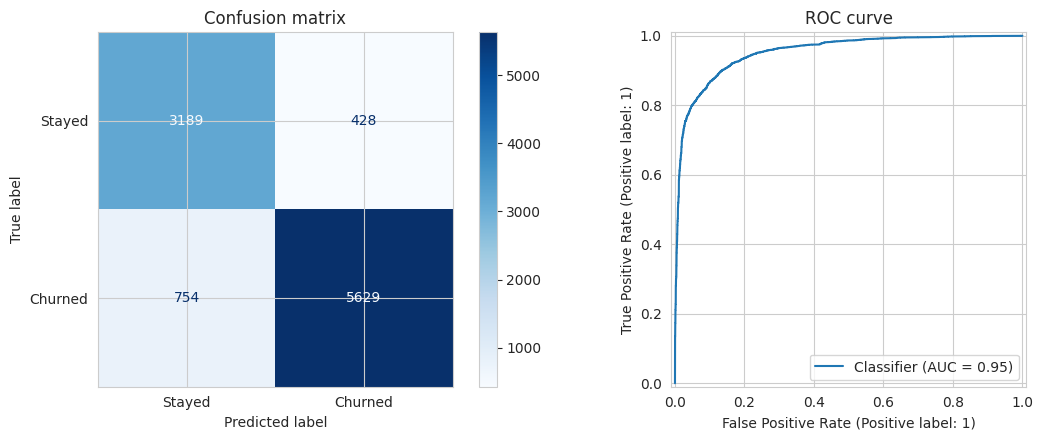

In [40]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stayed", "Churned"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1])
ax[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

### Which features matter most?

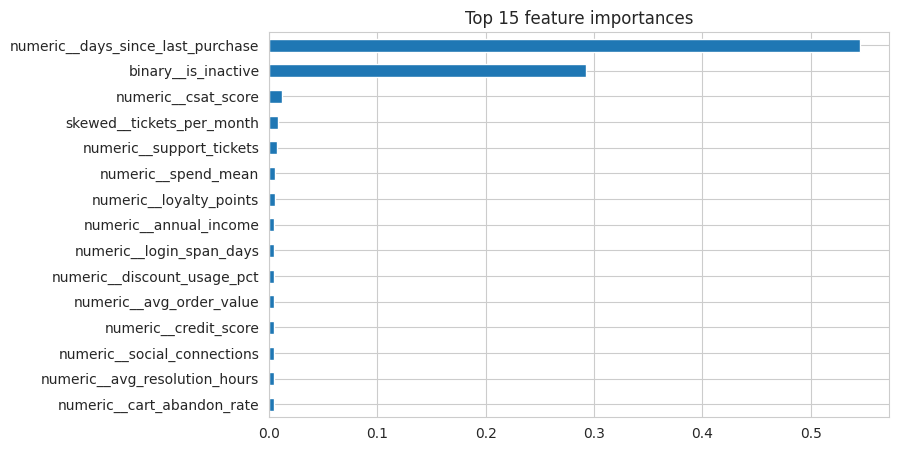

In [41]:
feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
importances = best_model.named_steps["random"].feature_importances_
imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh")
plt.title("Top 15 feature importances")
plt.show()

## Save the model

In [42]:
joblib.dump(best_model, "churn_model.pkl")
print("Saved churn_model.pkl")

Saved churn_model.pkl


In [43]:
# Test that the saved model loads and predicts
loaded = joblib.load("churn_model.pkl")
sample = X_test.iloc[:5]
print(loaded.predict(sample))
print(loaded.predict_proba(sample)[:, 1].round(3))

[0 1 1 1 1]
[0.119 0.87  0.835 0.839 0.852]


## Conclusion
- The tuned Random Forest and the Logistic Regression baseline are compared on train and test scores.
- `days_since_last_purchase`, `csat_score`, `support_tickets` and the engineered spend features drive churn.
- Next step: put `churn_model.pkl` behind a small Streamlit app so a user can enter customer details and get a churn probability.